In [2]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

def fuzzySystem_OP(pixel, vm):

    # pixelIN variables
    #x_pixelIN = np.arange(0, 4096, 1)
    #x_pixelOUT  = np.arange(0, 2, 1/4096)
    #x_pixelIN = np.linspace(0, 4095, 50)
    x_pixelIN = np.linspace(0, 1, 100)
    x_pixelOUT  = np.linspace(0, 1, 100)

    # Generate fuzzy membership functions
    pixelIN_sm = fuzz.trapmf(x_pixelIN, [0, 0, 0.15*vm, 0.6*vm])
    pixelIN_md = fuzz.trimf(x_pixelIN, [0.5*vm, vm, 1.4*vm])
    #pixelIN_la = fuzz.trapmf(x_pixelIN, [1.3*vm, 1.6*vm, 4095, 4095])
    pixelIN_la = fuzz.trapmf(x_pixelIN, [1.3*vm, 1.6*vm, 1, 1])
    pixelOUT_sm = fuzz.trapmf(x_pixelOUT, [0, 0, 0.05, 0.1])
    pixelOUT_md = fuzz.trimf(x_pixelOUT, [0.45, 0.5, 0.55])
    pixelOUT_la = fuzz.trapmf(x_pixelOUT, [0.9, 0.95, 1, 1])
    
    # Activation of fuzzy membership functions at vm using fuzz.interp_membership 
    pixelIN_level_sm = fuzz.interp_membership(x_pixelIN, pixelIN_sm, pixel)
    pixelIN_level_md = fuzz.interp_membership(x_pixelIN, pixelIN_md, pixel)
    pixelIN_level_la = fuzz.interp_membership(x_pixelIN, pixelIN_la, pixel)

    # Rules for OP
    rule1 = np.fmin(pixelIN_level_sm, pixelOUT_sm) # edge
    rule2 = np.fmin(pixelIN_level_md, pixelOUT_la) # liver
    rule3 = np.fmin(pixelIN_level_la, pixelOUT_md) # vessel
    
    # Aggregating the output membership functions
    aggregated = np.fmax(rule1, np.fmax(rule2, rule3))
    
    # Calculating the result
    output = fuzz.defuzz(x_pixelOUT, aggregated, 'centroid')
    output_activation = fuzz.interp_membership(x_pixelOUT, aggregated, output) # for plot
    
    return(output)

def fuzzySystem_IP(pixel, vm):

    # pixelIN variables
    #x_pixelIN = np.arange(0, 4096, 1)
    #x_pixelOUT  = np.arange(0, 2, 1/4096)
    #x_pixelIN = np.linspace(0, 4095, 20)
    x_pixelIN = np.linspace(0, 1, 20)
    x_pixelOUT  = np.linspace(0, 1, 20)

    # Generate fuzzy membership functions
    pixelIN_sm = fuzz.trapmf(x_pixelIN, [0, 0, 0.15*vm, 0.6*vm])
    pixelIN_md = fuzz.trimf(x_pixelIN, [0.5*vm, vm, 1.4*vm])
    #pixelIN_la = fuzz.trapmf(x_pixelIN, [1.3*vm, 1.6*vm, 4095, 4095])
    pixelIN_la = fuzz.trapmf(x_pixelIN, [1.3*vm, 1.6*vm, 1, 1])
    pixelOUT_sm = fuzz.trapmf(x_pixelOUT, [0, 0, 0.05, 0.1])
    pixelOUT_md = fuzz.trimf(x_pixelOUT, [0.45, 0.5, 0.55])
    pixelOUT_la = fuzz.trapmf(x_pixelOUT, [0.9, 0.95, 1, 1])

    # Activation of fuzzy membership functions at vm using fuzz.interp_membership 
    pixelIN_level_sm = fuzz.interp_membership(x_pixelIN, pixelIN_sm, pixel)
    pixelIN_level_md = fuzz.interp_membership(x_pixelIN, pixelIN_md, pixel)
    pixelIN_level_la = fuzz.interp_membership(x_pixelIN, pixelIN_la, pixel)
    
    # Rules for IP
    rule1 = np.fmin(pixelIN_level_sm, pixelOUT_md) # vessel
    rule2 = np.fmin(pixelIN_level_md, pixelOUT_la) # liver
    rule3 = np.fmin(pixelIN_level_la, pixelOUT_sm) # edge
    
    # Aggregating the output membership functions
    aggregated = np.fmax(rule1, np.fmax(rule2, rule3))
    
    # Calculating the result
    output = fuzz.defuzz(x_pixelOUT, aggregated, 'centroid')
    output_activation = fuzz.interp_membership(x_pixelOUT, aggregated, output) # for plot
    
    return(output)

## TESTE

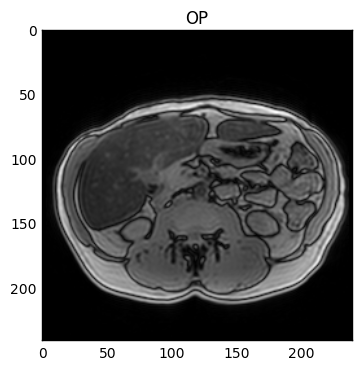

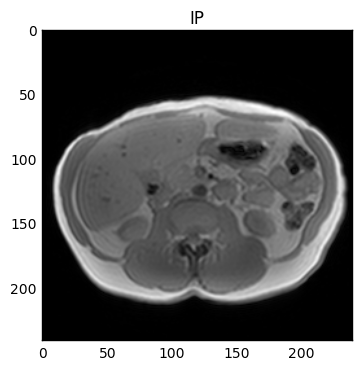

0.5404880046844482


In [3]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from time import time

start = time()

pixelOP = np.genfromtxt("op230.txt")
pixelIP = np.genfromtxt("ip431.txt")

plt.imshow(pixelOP, cmap='gray')
plt.title('OP')
plt.show()

plt.imshow(pixelIP, cmap='gray')
plt.title('IP')

plt.show()
print(time() - start)

[[ 0.  0.  0. ...,  0.  0.  0.]
 [ 0.  0.  0. ...,  0.  0.  0.]
 [ 0.  0.  0. ...,  0.  0.  0.]
 ..., 
 [ 0.  0.  0. ...,  0.  0.  0.]
 [ 0.  0.  0. ...,  0.  0.  0.]
 [ 0.  0.  0. ...,  0.  0.  0.]]
1102.0
[[ 0.  0.  0. ...,  0.  0.  0.]
 [ 0.  0.  0. ...,  0.  0.  0.]
 [ 0.  0.  0. ...,  0.  0.  0.]
 ..., 
 [ 0.  0.  0. ...,  0.  0.  0.]
 [ 0.  0.  0. ...,  0.  0.  0.]
 [ 0.  0.  0. ...,  0.  0.  0.]]
0.269108669109


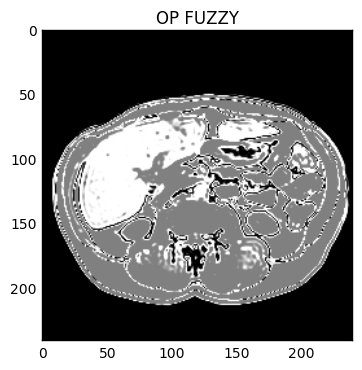

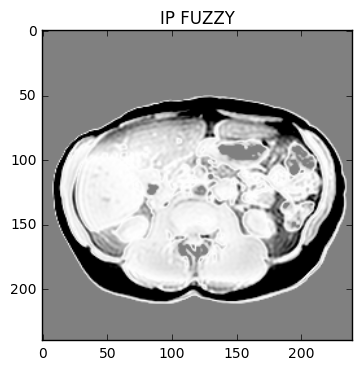

80.4177668094635


In [4]:
start = time()

imgOP = np.zeros(pixelOP.shape)
imgIP = np.zeros(pixelIP.shape)

print(pixelOP)
print(np.amax(pixelOP))

pixelOP *= 1.0/4095.0
pixelIP *= 1.0/4095.0

print(pixelOP)
print(np.amax(pixelOP))

vmed_op = 230.0/4095.0
vmed_ip = 431.0/4095.0

for index, pixel in np.ndenumerate(pixelOP):
    imgOP[index] = fuzzySystem_OP(pixel, vmed_op)

for index, pixel in np.ndenumerate(pixelIP):
    imgIP[index] = fuzzySystem_IP(pixel, vmed_ip)

plt.imshow(imgOP, cmap='gray')
plt.title('OP FUZZY')
plt.show()

plt.imshow(imgIP, cmap='gray')
plt.title('IP FUZZY')
plt.show()

print(time() - start)

In [6]:
"""start = time()

imgAND = np.zeros(pixelOP.shape)

for index, pixel in np.ndenumerate(imgOP):
    imgAND[index] = np.fmin(imgOP[index],imgIP[index])

print(time() - start)

plt.imshow(imgAND, cmap='gray')
plt.title('OP AND')
plt.show()"""

"start = time()\n\nimgAND = np.zeros(pixelOP.shape)\n\nfor index, pixel in np.ndenumerate(imgOP):\n    imgAND[index] = np.fmin(imgOP[index],imgIP[index])\n\nprint(time() - start)\n\nplt.imshow(imgAND, cmap='gray')\nplt.title('OP AND')\nplt.show()"

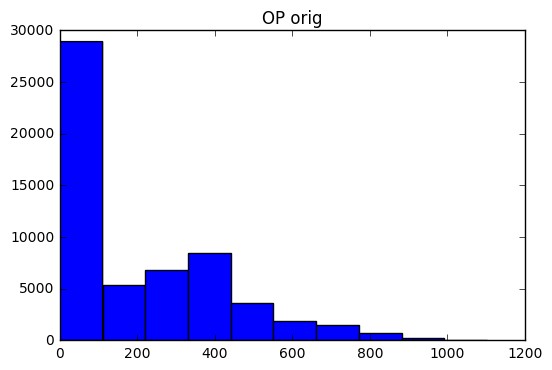

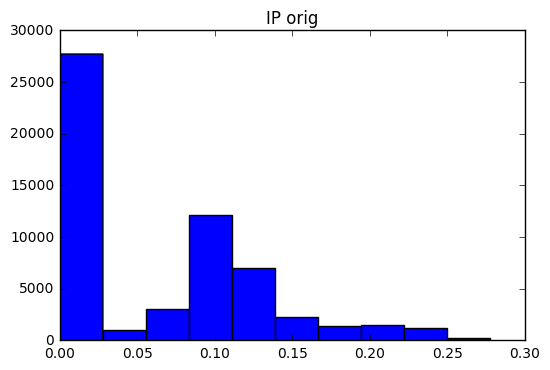

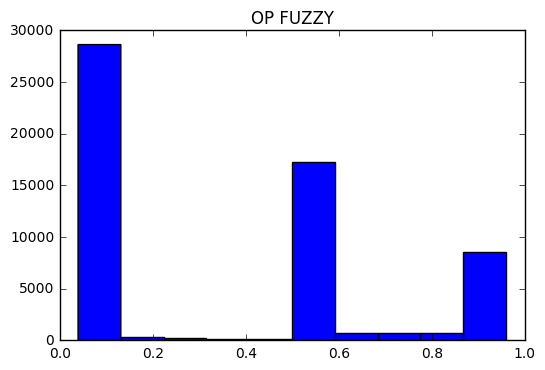

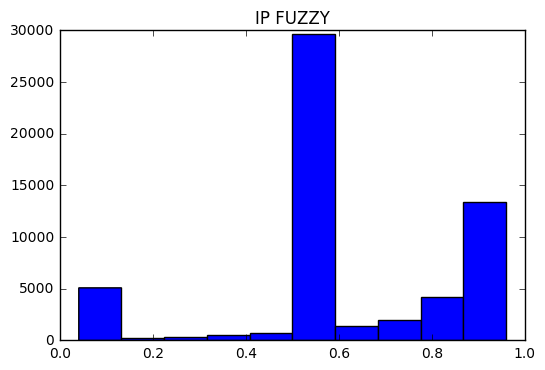

In [8]:
plt.hist(pixelOP.flatten())
plt.title('OP orig')
plt.show()

plt.hist(pixelIP.flatten())
plt.title('IP orig')
plt.show()

plt.hist(imgOP.flatten())
plt.title('OP FUZZY')
plt.show()

plt.hist(imgIP.flatten())
plt.title('IP FUZZY')
plt.show()

In [ ]:
plt.figure(1)

plt.subplot(221)
plt.imshow(pixelOP, cmap='gray')
plt.title('OP')

plt.subplot(222)
plt.imshow(imgOP, cmap='gray')
plt.title('OP FUZZY')

plt.show()

In [ ]:
plt.figure(1)

plt.subplot(221)
plt.imshow(pixelIP, cmap='gray')
plt.title('IP')

plt.subplot(222)
plt.imshow(imgIP, cmap='gray')
plt.title('IP FUZZY')

plt.show()

In [ ]:
plt.imshow(imgOP, cmap='gray')
plt.title('OP FUZZY')
plt.show()

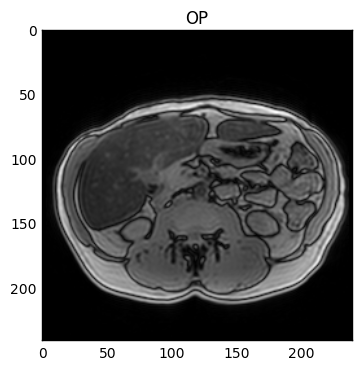

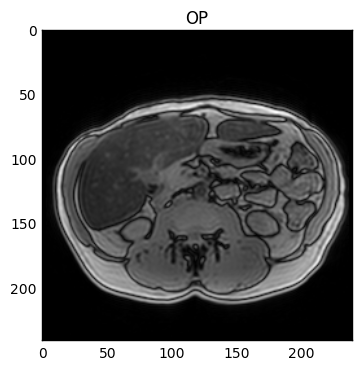

In [7]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from time import time

pixelOP = np.genfromtxt("op230.txt")

plt.imshow(pixelOP, cmap='gray')
plt.title('OP')
plt.show()

image = np.genfromtxt("op230.txt")
image *= 255.0/image.max()    # Uses 1 division and image.size multiplications
plt.imshow(image, cmap='gray')
plt.title('OP')
plt.show()

In [ ]:
a = np.array([[1,1], [1,2]])
print(a)
print(a.flatten())

plt.hist(a)
plt.show()

plt.hist(a.flatten())
plt.show()

C:\Users\gaf_f\Anaconda3\lib\site-packages\skimage\util\dtype.py:110: UserWarning: Possible precision loss when converting from float64 to uint16
  "%s to %s" % (dtypeobj_in, dtypeobj))


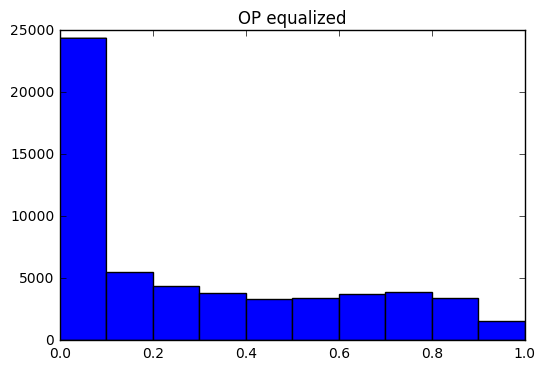

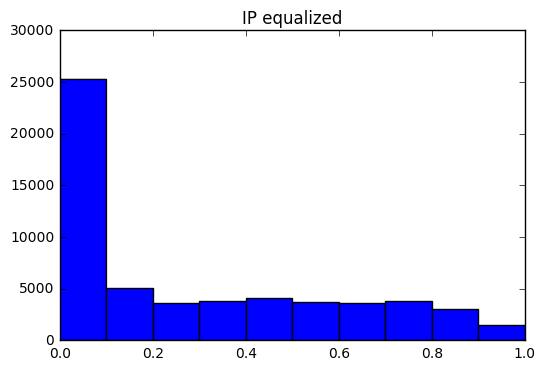

In [22]:
from skimage import exposure

pixelOP = np.genfromtxt("op230.txt")
pixelIP = np.genfromtxt("ip431.txt")

pixelOP *= 1.0/4095.0
pixelIP *= 1.0/4095.0

imOP = exposure.equalize_adapthist(pixelOP, nbins=4096)
imIP = exposure.equalize_adapthist(pixelIP, nbins=4096)

plt.hist(imOP.flatten())
plt.title('OP equalized')
plt.show()

plt.hist(imIP.flatten())
plt.title('IP equalized')
plt.show()

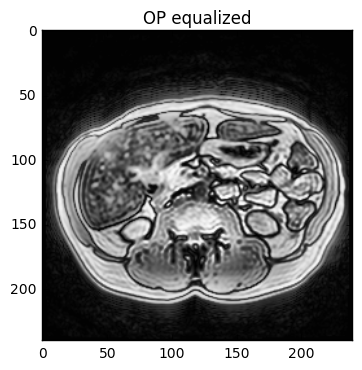

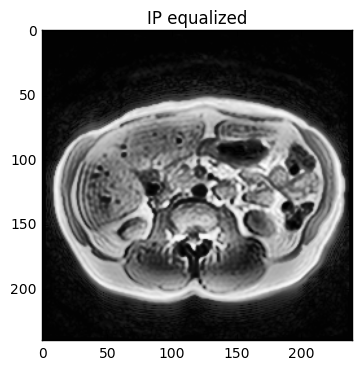

In [23]:
plt.imshow(imOP, cmap='gray')
plt.title('OP equalized adapthist')
plt.show()

plt.imshow(imIP, cmap='gray')
plt.title('IP equalized adapthist')
plt.show()

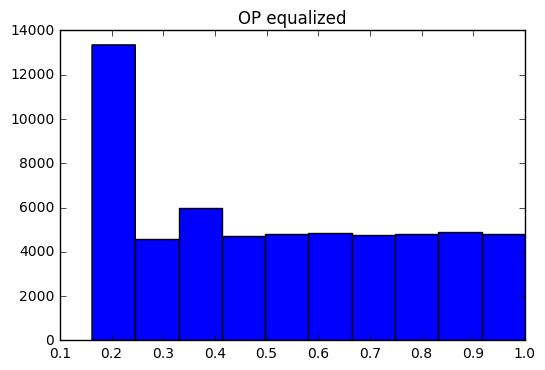

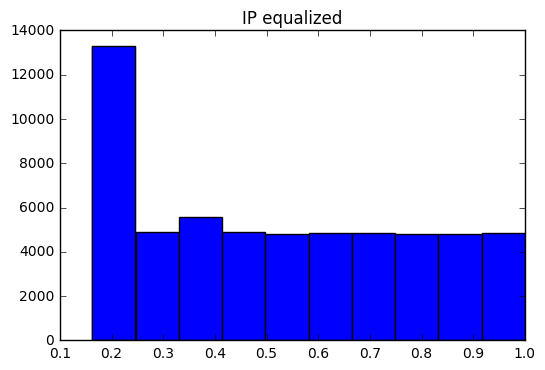

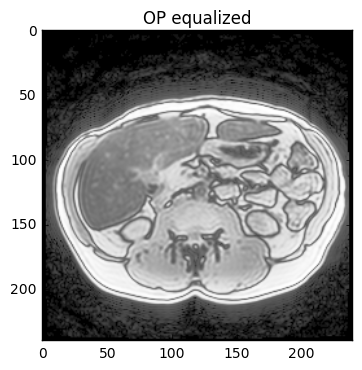

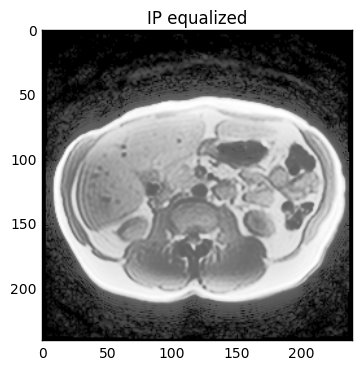

In [25]:
from skimage import exposure

pixelOP = np.genfromtxt("op230.txt")
pixelIP = np.genfromtxt("ip431.txt")

pixelOP *= 1.0/4095.0
pixelIP *= 1.0/4095.0

imOP1 = exposure.equalize_hist(pixelOP, nbins=4096)
imIP1 = exposure.equalize_hist(pixelIP, nbins=4096)

plt.hist(imOP1.flatten())
plt.title('OP equalized')
plt.show()

plt.hist(imIP1.flatten())
plt.title('IP equalized')
plt.show()

plt.imshow(imOP1, cmap='gray')
plt.title('OP equalized hist')
plt.show()

plt.imshow(imIP1, cmap='gray')
plt.title('IP equalized hist')
plt.show()

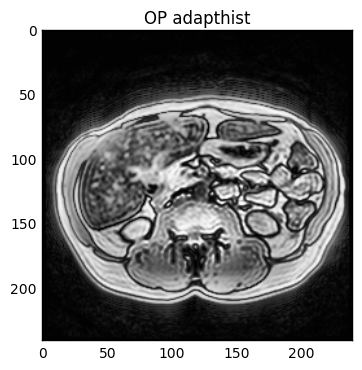

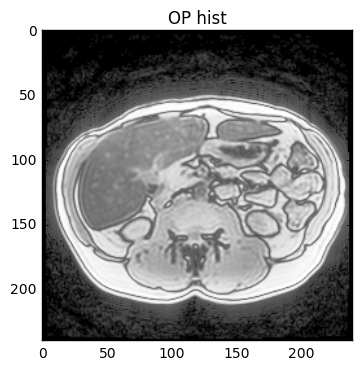

In [32]:
plt.imshow(imOP, cmap='gray')
plt.title('OP adapthist')
plt.show()

plt.imshow(imOP1, cmap='gray')
plt.title('OP hist')
plt.show()

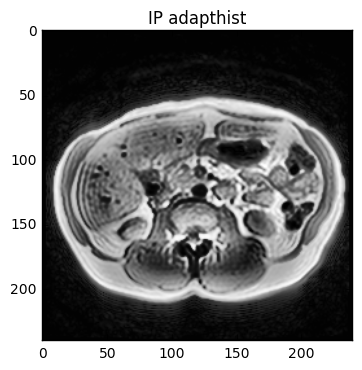

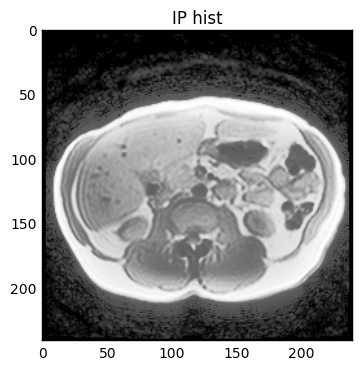

In [33]:
plt.imshow(imIP, cmap='gray')
plt.title('IP adapthist')
plt.show()

plt.imshow(imIP1, cmap='gray')
plt.title('IP hist')
plt.show()

EQUALIZE_ADAPTHIST


C:\Users\gaf_f\Anaconda3\lib\site-packages\skimage\util\dtype.py:110: UserWarning: Possible precision loss when converting from float64 to uint16
  "%s to %s" % (dtypeobj_in, dtypeobj))


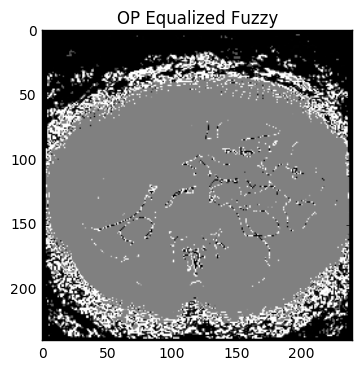

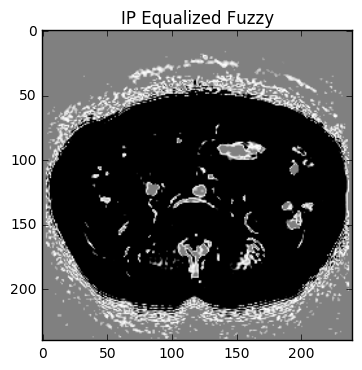

In [35]:
print('EQUALIZE_ADAPTHIST')

pixelOP = np.genfromtxt("op230.txt")
pixelIP = np.genfromtxt("ip431.txt")

pixelOP *= 1.0/4095.0
pixelIP *= 1.0/4095.0

imOP = exposure.equalize_adapthist(pixelOP, nbins=4096)
imIP = exposure.equalize_adapthist(pixelIP, nbins=4096)

vmed_op = 230.0/4095.0
vmed_ip = 431.0/4095.0

imgOP = np.zeros(pixelOP.shape)
imgIP = np.zeros(pixelIP.shape)

for index, pixel in np.ndenumerate(imOP):
    imgOP[index] = fuzzySystem_OP(pixel, vmed_op)

for index, pixel in np.ndenumerate(imIP):
    imgIP[index] = fuzzySystem_IP(pixel, vmed_ip)

plt.imshow(imgOP, cmap='gray')
plt.title('OP Equalized Fuzzy')
plt.show()

plt.imshow(imgIP, cmap='gray')
plt.title('IP Equalized Fuzzy')
plt.show()

EQUALIZE_HIST


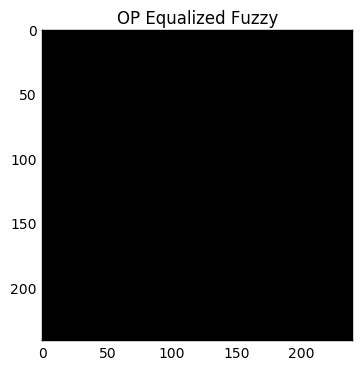

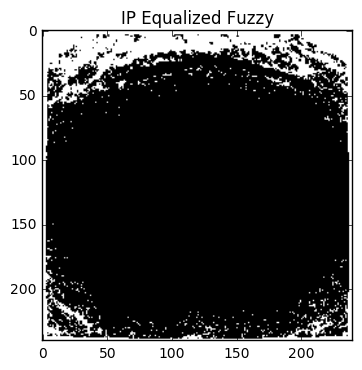

In [36]:
print('EQUALIZE_HIST')

pixelOP = np.genfromtxt("op230.txt")
pixelIP = np.genfromtxt("ip431.txt")

pixelOP *= 1.0/4095.0
pixelIP *= 1.0/4095.0

imOP1 = exposure.equalize_hist(pixelOP, nbins=4096)
imIP1 = exposure.equalize_hist(pixelIP, nbins=4096)

vmed_op = 230.0/4095.0
vmed_ip = 431.0/4095.0

imgOP1 = np.zeros(pixelOP.shape)
imgIP1 = np.zeros(pixelIP.shape)

for index, pixel in np.ndenumerate(imOP1):
    imgOP1[index] = fuzzySystem_OP(pixel, vmed_op)

for index, pixel in np.ndenumerate(imIP1):
    imgIP1[index] = fuzzySystem_IP(pixel, vmed_ip)

plt.imshow(imgOP1, cmap='gray')
plt.title('OP Equalized Fuzzy')
plt.show()

plt.imshow(imgIP1, cmap='gray')
plt.title('IP Equalized Fuzzy')
plt.show()

In [57]:
from skimage import segmentation as seg

pixelOP = np.genfromtxt("op230.txt")
pixelIP = np.genfromtxt("ip431.txt")

pixelOP *= 1.0/4095.0
pixelIP *= 1.0/4095.0

imOP = skimage.segmentation.watershed(pixelOP,0)

plt.imshow(imOP, cmap='gray')
plt.show()

NameError: name 'skimage' is not defined

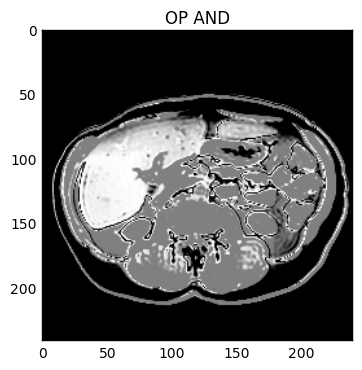

In [66]:
pixelOP = np.genfromtxt("op230.txt")
pixelIP = np.genfromtxt("ip431.txt")

pixelOP *= 1.0/4095.0
pixelIP *= 1.0/4095.0

imgOP = np.zeros(pixelOP.shape)
imgIP = np.zeros(pixelIP.shape)

vmed_op = 230.0/4095.0
vmed_ip = 431.0/4095.0

for index, pixel in np.ndenumerate(pixelOP):
    imgOP[index] = fuzzySystem_OP(pixel, vmed_op)

for index, pixel in np.ndenumerate(pixelIP):
    imgIP[index] = fuzzySystem_IP(pixel, vmed_ip)

#plt.imshow(imgOP, cmap='gray')
#plt.title('OP FUZZY')
#plt.show()

#plt.imshow(imgIP, cmap='gray')
#plt.title('IP FUZZY')
#plt.show()

####################################################

imgAND = np.zeros(pixelOP.shape)

for index, pixel in np.ndenumerate(imgOP):
    imgAND[index] = np.fmin(imgOP[index],imgIP[index])


plt.imshow(imgAND, cmap='gray')
plt.title('OP AND')
plt.show()

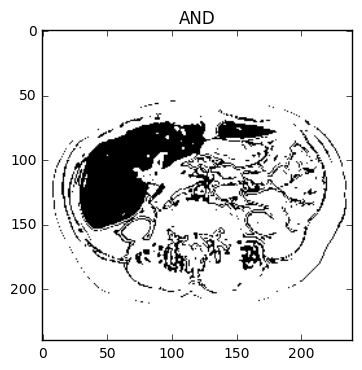

In [68]:
from skimage import filters
val = filters.threshold_otsu(imgAND)
mask = imgAND < 0.6

plt.imshow(mask, cmap='gray')
plt.title('AND')
plt.show()

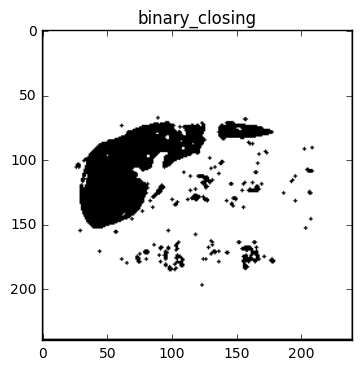

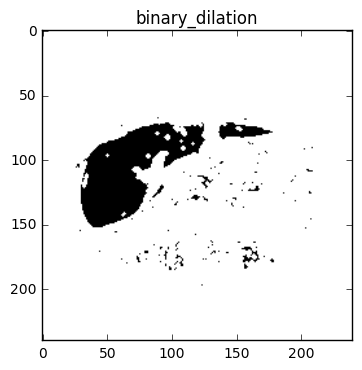

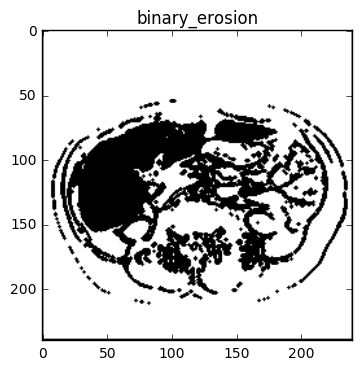

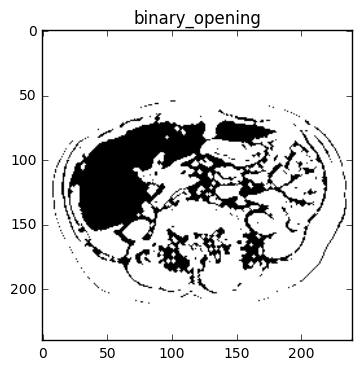

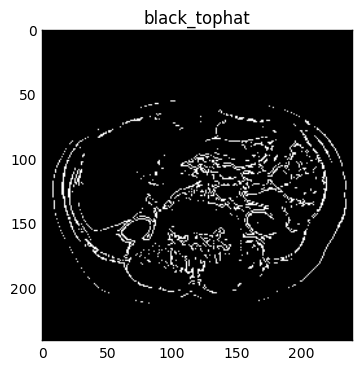

In [74]:
from skimage import morphology

img = morphology.binary_closing(mask)
plt.imshow(img, cmap='gray')
plt.title('binary_closing')
plt.show()

img1 = morphology.binary_dilation(mask)
plt.imshow(img1, cmap='gray')
plt.title('binary_dilation')
plt.show()

img2 = morphology.binary_erosion(mask)
plt.imshow(img2, cmap='gray')
plt.title('binary_erosion')
plt.show()

img3 = morphology.binary_opening(mask)
plt.imshow(img3, cmap='gray')
plt.title('binary_opening')
plt.show()

img4 = morphology.black_tophat(mask)
plt.imshow(img4, cmap='gray')
plt.title('black_tophat')
plt.show()

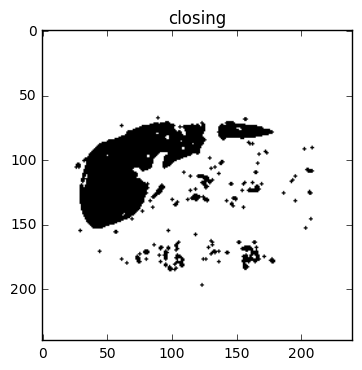

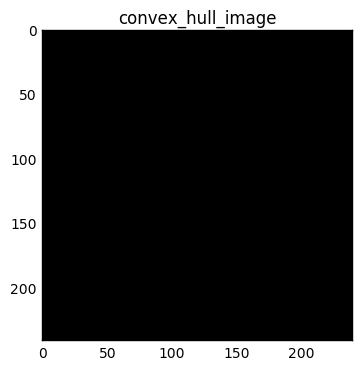

In [76]:
img5 = morphology.closing(mask)
plt.imshow(img5, cmap='gray')
plt.title('closing')
plt.show()

img6 = morphology.convex_hull_image(mask)
plt.imshow(img6, cmap='gray')
plt.title('convex_hull_image')
plt.show()

img6 = morphology.convex_hull_image(mask)
plt.imshow(img6, cmap='gray')
plt.title('convex_hull_image')
plt.show()

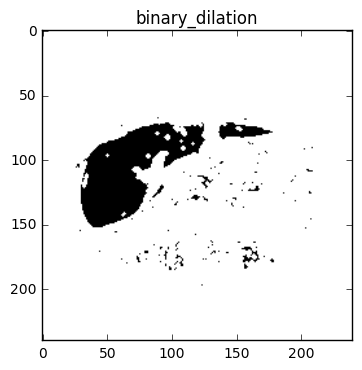

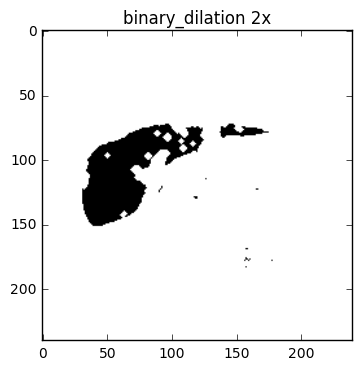

In [79]:
img1 = morphology.binary_dilation(mask)
plt.imshow(img1, cmap='gray')
plt.title('binary_dilation')
plt.show()

In [86]:
import skimage

img10 = skimage.morphology.h_minima(mask,0)
plt.imshow(img10, cmap='gray')
plt.title('binary_dilation')
plt.show()

AttributeError: module 'skimage.morphology' has no attribute 'h_minima'